# 01 · EDA de la OBT de Centinela

**Pregunta del proyecto (PSet 1):** puntuar cada transacción con tarjeta según su riesgo de fraude en el momento de la autorización.

**Datos:** snapshot local en Parquet de `CENTINELA.OBT.TRANSACCIONES_OBT` (creado con `python src/datos.py`). El hash se verifica al cargar.

**Alcance de la EDA:** las estadísticas que guían decisiones de modelado se calculan **solo con la partición de entrenamiento** (ene-2019 a jun-2020). La partición de prueba (jul-dic 2020) solo se usa para contar filas y prevalencia, sin mirar sus relaciones, para no contaminar el hold-out.

Las tablas y figuras se guardan en `pset_3/docs/eda/`.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

from datos import cargar_obt, metadatos_snapshot
from pipeline import EXCLUIDAS, OBJETIVO, SEMILLA

DOCS = Path.cwd().parent / "docs" / "eda"
DOCS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50)

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(DOCS / nombre, dpi=120)
    plt.close(fig)
    display(Image(filename=str(DOCS / nombre)))

meta = metadatos_snapshot()
print(json.dumps(meta, indent=2, ensure_ascii=False))
df = cargar_obt()
ent = df[df["particion_temporal"] == "entrenamiento"].copy()
pru = df[df["particion_temporal"] == "prueba"]
print("OBT:", df.shape, "| entrenamiento:", ent.shape, "| prueba:", pru.shape)

{
  "tabla_origen": "CENTINELA.OBT.TRANSACCIONES_OBT",
  "fecha_corte_snapshot": "2026-11-18 14:52:45.511 -0800",
  "filas": 1852394,
  "columnas": 40,
  "tasa_fraude": 0.005210014716091717,
  "sha256": "9be410f73fb8c090e7647fc27559665c28431d29a0652548d16d8b932d9e9bce",
  "segundos_descarga": 18.0
}


OBT: (1852394, 40) | entrenamiento: (1326733, 40) | prueba: (525661, 40)


## 1. Tamaño, tipos y valores faltantes por columna

In [2]:
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "pct_nulos": (100 * df.isna().mean()).round(3),
    "valores_distintos": df.nunique(),
    "uso_en_modelo": ["excluida: " + EXCLUIDAS[c] if c in EXCLUIDAS else ("target" if c == OBJETIVO else "candidata")
                      for c in df.columns],
})
perfil.to_csv(DOCS / "perfil_columnas.csv")
print(f"Filas: {len(df):,} | columnas: {df.shape[1]} | memoria: {df.memory_usage(deep=True).sum()/1e6:,.0f} MB")
perfil

Filas: 1,852,394 | columnas: 40 | memoria: 2,059 MB


,tipo,nulos,pct_nulos,valores_distintos,uso_en_modelo
trans_num,object,0,0.000,1852394,excluida: identificador de la transacción
trans_ts,datetime64[ns],0,0.000,1819551,excluida: marca de tiempo: se usa solo para or...
fecha,object,0,0.000,730,excluida: fecha calendario: el modelo debe gen...
anio,int16,0,0.000,2,excluida: año: no se repite en el futuro (2019...
mes,int8,0,0.000,12,excluida: mes: prueba (jul-dic) y entrenamient...
dia_semana,int8,0,0.000,7,candidata
es_fin_de_semana,bool,0,0.000,2,candidata
hora,int8,0,0.000,24,candidata
es_nocturna,bool,0,0.000,2,candidata
franja,object,0,0.000,4,excluida: redundante con hora


Las únicas columnas con nulos son `segundos_desde_anterior`, `monto_medio_previo` y `monto_relativo`. Son nulos **estructurales**: corresponden a la primera transacción de cada cliente, que no tiene historial previo (999 clientes, lo validó el PSet 2). No son datos perdidos: se imputan con la mediana más un **indicador de faltante** dentro del pipeline.

## 2. Estadística descriptiva (entrenamiento)

In [3]:
numericas = ["amt", "distancia_km", "edad_en_transaccion", "city_pop", "n_tx_1h", "gasto_1h", "n_tx_24h",
             "gasto_24h", "segundos_desde_anterior", "n_tx_previas", "monto_medio_previo", "monto_relativo", "hora"]
desc = ent[numericas].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T
desc["asimetria"] = ent[numericas].skew()
desc.to_csv(DOCS / "descriptivos_entrenamiento.csv")
desc.round(3)

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,asimetria
amt,1326733.0,70.325,159.765,1.000,1.260,9.650,47.490,83.120,196.220,546.370,28948.900,41.935
distancia_km,1326733.0,76.113,29.112,0.022,11.111,55.341,78.226,98.495,120.491,132.044,152.117,-0.236
edad_en_transaccion,1326733.0,45.504,17.398,13.000,16.000,32.000,43.000,57.000,79.000,91.000,95.000,0.611
city_pop,1326733.0,88869.720,302060.362,23.000,53.000,743.000,2456.000,20328.000,525713.000,1577385.000,2906700.000,5.592
n_tx_1h,1326733.0,0.190,0.463,0.000,0.000,0.000,0.000,0.000,1.000,2.000,6.000,2.736
gasto_1h,1326733.0,14.601,96.321,0.000,0.000,0.000,0.000,0.000,79.340,221.027,27390.120,45.639
n_tx_24h,1326733.0,3.901,3.086,0.000,0.000,2.000,3.000,5.000,10.000,14.000,35.000,1.390
gasto_24h,1326733.0,276.268,422.803,0.000,0.000,67.230,173.300,346.120,861.330,1737.447,29773.370,12.045
segundos_desde_anterior,1325749.0,32318.833,47187.162,0.000,190.000,5980.000,16471.000,39988.000,113518.600,231663.000,1341471.000,4.284
n_tx_previas,1326733.0,930.130,693.918,0.000,13.000,364.000,795.000,1373.000,2299.000,2875.000,3200.000,0.816


In [4]:
cat = (ent.groupby("categoria")
         .agg(transacciones=("is_fraud", "size"), fraudes=("is_fraud", "sum"), tasa_fraude=("is_fraud", "mean"),
              monto_mediano=("amt", "median"))
         .sort_values("tasa_fraude", ascending=False))
cat["tasa_fraude_pct"] = (100 * cat["tasa_fraude"]).round(3)
cat.to_csv(DOCS / "fraude_por_categoria.csv")
cat.drop(columns="tasa_fraude")

,transacciones,fraudes,monto_mediano,tasa_fraude_pct
categoria,,,,
shopping_net,99845,1746,8.43,1.749
misc_net,64672,933,9.84,1.443
grocery_pos,126287,1774,105.10,1.405
shopping_pos,119369,856,7.77,0.717
gas_transport,134457,625,62.83,0.465
misc_pos,81499,254,13.96,0.312
grocery_net,46464,135,50.93,0.291
travel,41518,119,6.25,0.287
entertainment,96199,238,50.78,0.247


## 3. Distribución del target y desbalance

In [5]:
prev = pd.DataFrame({
    "filas": [len(ent), len(pru), len(df)],
    "fraudes": [int(ent[OBJETIVO].sum()), int(pru[OBJETIVO].sum()), int(df[OBJETIVO].sum())],
}, index=["entrenamiento (ene-2019 a jun-2020)", "prueba (jul-dic 2020)", "total"])
prev["tasa_fraude_pct"] = (100 * prev["fraudes"] / prev["filas"]).round(3)
prev["legitimas_por_fraude"] = ((prev["filas"] - prev["fraudes"]) / prev["fraudes"]).round(0)
prev.to_csv(DOCS / "desbalance.csv")
prev

,filas,fraudes,tasa_fraude_pct,legitimas_por_fraude
entrenamiento (ene-2019 a jun-2020),1326733,7639,0.576,173.0
prueba (jul-dic 2020),525661,2012,0.383,260.0
total,1852394,9651,0.521,191.0


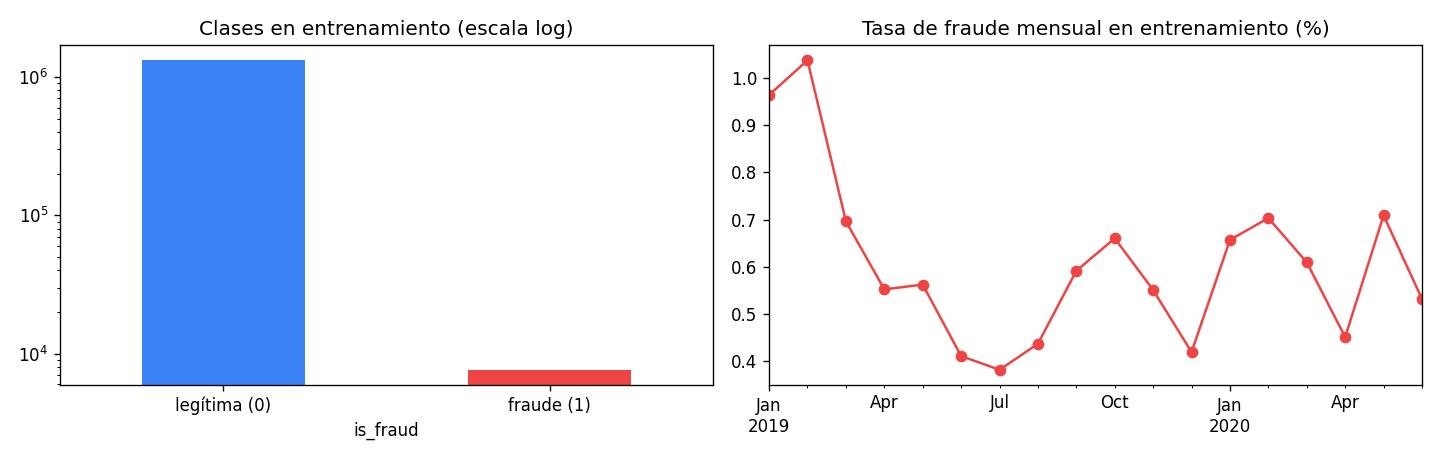

In [6]:
mensual = ent.set_index("trans_ts").resample("MS")[OBJETIVO].agg(["mean", "sum"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ent[OBJETIVO].value_counts().sort_index().plot.bar(ax=ax[0], color=["#3b82f6", "#ef4444"], logy=True)
ax[0].set_title("Clases en entrenamiento (escala log)"); ax[0].set_xticklabels(["legítima (0)", "fraude (1)"], rotation=0)
(100 * mensual["mean"]).plot(ax=ax[1], marker="o", color="#ef4444")
ax[1].set_title("Tasa de fraude mensual en entrenamiento (%)"); ax[1].set_xlabel("")
guardar(fig, "target_distribucion.png")

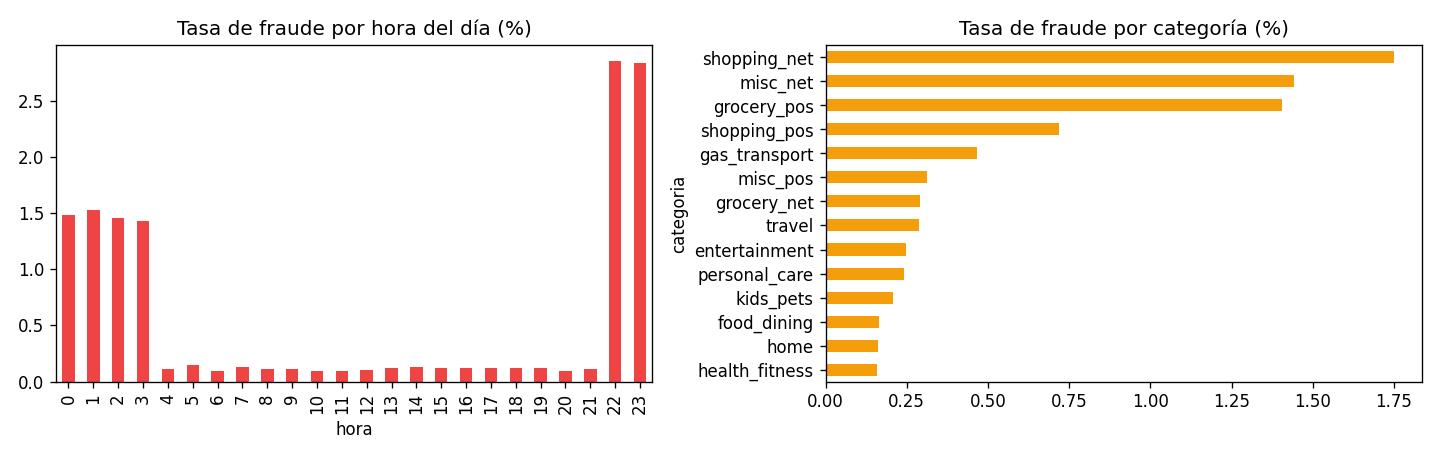

Tasa de fraude 22:00-03:59 vs resto (%): 2.077 vs 0.115


In [7]:
por_hora = ent.groupby("hora")[OBJETIVO].mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
por_hora.plot.bar(ax=ax[0], color="#ef4444"); ax[0].set_title("Tasa de fraude por hora del día (%)")
(cat["tasa_fraude"] * 100).sort_values().plot.barh(ax=ax[1], color="#f59e0b"); ax[1].set_title("Tasa de fraude por categoría (%)")
guardar(fig, "fraude_por_hora_y_categoria.png")
por_hora.round(3).to_csv(DOCS / "fraude_por_hora.csv")
print("Tasa de fraude 22:00-03:59 vs resto (%):",
      round(100 * ent.loc[ent["es_nocturna"], OBJETIVO].mean(), 3), "vs", round(100 * ent.loc[~ent["es_nocturna"], OBJETIVO].mean(), 3))

## 4. Valores atípicos: IQR (diagrama de caja) y Z-score ≥ 3

- **IQR:** atípico si el valor está fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR].
- **Z-score:** atípico si |z| ≥ 3.

Para cada variable se reporta también **la tasa de fraude dentro de los atípicos**, porque en este problema un atípico puede ser justamente la señal y no un error.

In [8]:
filas = []
for c in numericas:
    x = ent[c].astype(float)
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    at_iqr = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
    z = (x - x.mean()) / x.std()
    at_z = z.abs() >= 3
    filas.append({"variable": c, "lim_inf_iqr": q1 - 1.5 * iqr, "lim_sup_iqr": q3 + 1.5 * iqr,
                  "atipicos_iqr": int(at_iqr.sum()), "pct_iqr": 100 * at_iqr.mean(),
                  "tasa_fraude_atipicos_iqr_pct": 100 * ent.loc[at_iqr, OBJETIVO].mean() if at_iqr.any() else np.nan,
                  "atipicos_z3": int(at_z.sum()), "pct_z3": 100 * at_z.mean(),
                  "tasa_fraude_atipicos_z3_pct": 100 * ent.loc[at_z, OBJETIVO].mean() if at_z.any() else np.nan})
atipicos = pd.DataFrame(filas).set_index("variable")
atipicos.to_csv(DOCS / "atipicos_iqr_zscore.csv")
atipicos.round(3)

,lim_inf_iqr,lim_sup_iqr,atipicos_iqr,pct_iqr,tasa_fraude_atipicos_iqr_pct,atipicos_z3,pct_z3,tasa_fraude_atipicos_z3_pct
variable,,,,,,,,
amt,-100.555,193.325,68835,5.188,8.439,13121,0.989,27.925
distancia_km,-9.390,163.227,0,0.000,NaN,0,0.000,NaN
edad_en_transaccion,-5.500,94.500,248,0.019,0.000,0,0.000,NaN
city_pop,-28634.500,49705.500,248358,18.720,0.600,33599,2.532,0.577
n_tx_1h,0.000,0.000,218403,16.462,1.523,29516,2.225,4.286
gasto_1h,0.000,0.000,218403,16.462,1.523,8413,0.634,30.120
n_tx_24h,-2.500,9.500,73138,5.513,0.250,16149,1.217,0.124
gasto_24h,-351.105,764.455,85745,6.463,6.456,17329,1.306,23.464
segundos_desde_anterior,-45032.000,91000.000,99484,7.498,0.191,26953,2.032,0.204


/tmp/ipykernel_14495/2152334962.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(datos, labels=["legítima", "fraude"], showfliers=True, flierprops={"markersize": 1.5, "alpha": .3})
/tmp/ipykernel_14495/2152334962.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(datos, labels=["legítima", "fraude"], showfliers=True, flierprops={"markersize": 1.5, "alpha": .3})
/tmp/ipykernel_14495/2152334962.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(datos, labels=["legítima", "fraude"], showfliers=True, flierprops={"markersize": 1.5, "alpha": .3})
/tmp/ipykernel_14495/2152334962.py:6: Ma

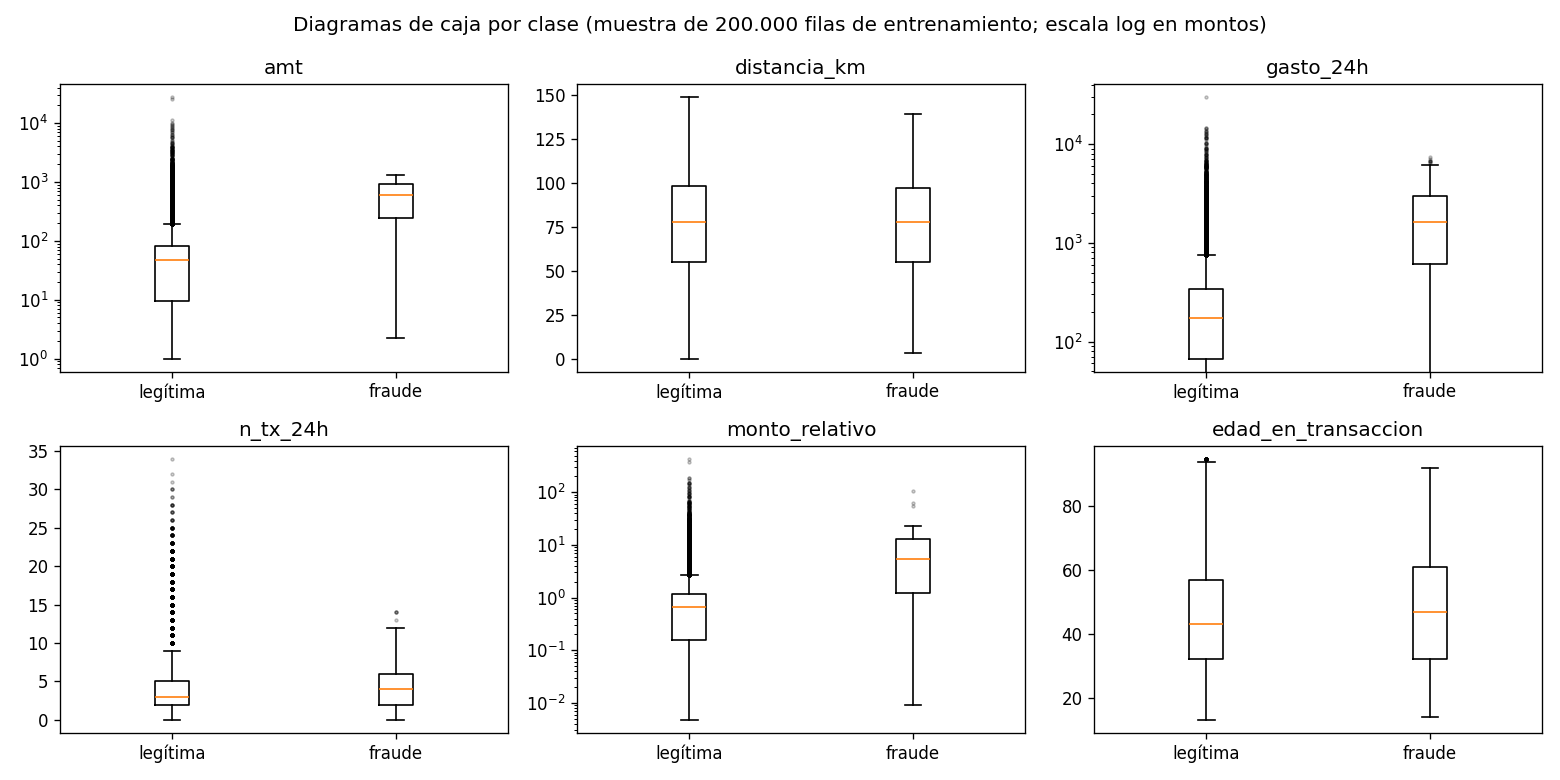

In [9]:
muestra = ent.sample(200_000, random_state=SEMILLA)
vars_box = ["amt", "distancia_km", "gasto_24h", "n_tx_24h", "monto_relativo", "edad_en_transaccion"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), vars_box):
    datos = [muestra.loc[muestra[OBJETIVO] == k, c].dropna() for k in (0, 1)]
    ax.boxplot(datos, labels=["legítima", "fraude"], showfliers=True, flierprops={"markersize": 1.5, "alpha": .3})
    ax.set_title(c)
    if c in ("amt", "gasto_24h", "monto_relativo"):
        ax.set_yscale("log")
fig.suptitle("Diagramas de caja por clase (muestra de 200.000 filas de entrenamiento; escala log en montos)")
guardar(fig, "boxplots_por_clase.png")

## 5. Relación del target con las variables: Spearman

**Por qué Spearman y no Pearson:**
- `amt`, `gasto_24h`, `city_pop` y `monto_relativo` tienen colas muy largas (ver la asimetría en la sección 2). Pearson mide relaciones **lineales** y queda dominado por esos extremos.
- Spearman usa **rangos**: es robusto a los atípicos y capta relaciones **monótonas no lineales**, como "a mayor monto, más fraude".
- Con un target binario, Pearson equivale a la correlación punto-biserial, que tiene la misma sensibilidad a las colas.

Las dos se calculan para mostrar la diferencia.

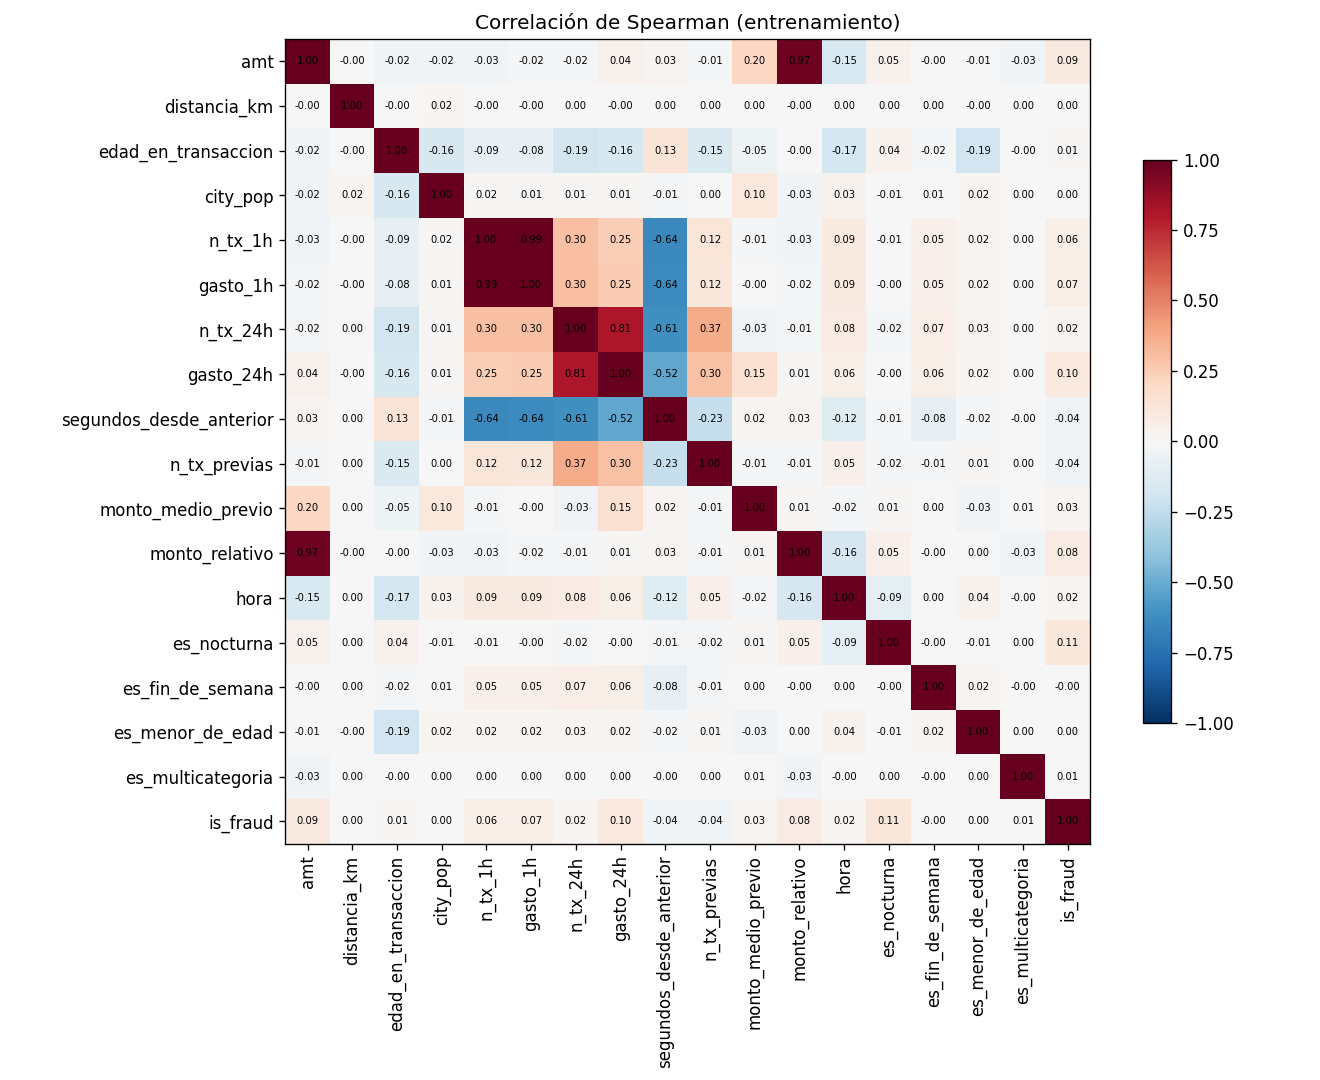

,spearman_con_is_fraud,pearson_con_is_fraud
es_nocturna,0.1100,0.1100
gasto_24h,0.0956,0.2966
amt,0.0878,0.2197
monto_relativo,0.0803,0.1712
gasto_1h,0.0665,0.3157
n_tx_1h,0.0592,0.0801
segundos_desde_anterior,-0.0387,-0.0177
n_tx_previas,-0.0382,-0.0335
monto_medio_previo,0.0272,0.1687
hora,0.0223,0.0137


In [10]:
cols = numericas + ["es_nocturna", "es_fin_de_semana", "es_menor_de_edad", "es_multicategoria", OBJETIVO]
m = ent[cols].astype(float)
spearman = m.corr(method="spearman")
pearson_target = m.corr(method="pearson")[OBJETIVO]
rel = pd.DataFrame({"spearman_con_is_fraud": spearman[OBJETIVO], "pearson_con_is_fraud": pearson_target}).drop(OBJETIVO)
rel = rel.reindex(rel["spearman_con_is_fraud"].abs().sort_values(ascending=False).index)
rel.to_csv(DOCS / "correlacion_con_target.csv")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(spearman.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{spearman.values[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=.7); ax.set_title("Correlación de Spearman (entrenamiento)")
guardar(fig, "heatmap_spearman.png")
rel.round(4)

In [11]:
# Pares de variables muy correlacionadas entre sí (|rho| >= 0,8): redundancia para el modelo lineal
pares = (spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), 1)).stack()
         .rename("rho").reset_index().query("abs(rho) >= 0.8").sort_values("rho", key=abs, ascending=False))
pares.to_csv(DOCS / "pares_redundantes.csv", index=False)
pares

,level_0,level_1,rho
62,n_tx_1h,gasto_1h,0.994431
10,amt,monto_relativo,0.973086
87,n_tx_24h,gasto_24h,0.808135


**Lectura de las correlaciones:**
- En `gasto_1h`, `gasto_24h` y `amt`, **Pearson sale bastante más alto que Spearman**. La asociación con el fraude está en los **extremos**: pocos fraudes con montos o gastos muy altos, que Pearson sobrepondera. Spearman mide la asociación de orden en toda la distribución.
- Las dos coinciden en el **signo** de las variables principales: noche, gasto y monto positivos; historial (`n_tx_previas`, `segundos_desde_anterior`) negativo.
- Ninguna correlación individual pasa de ~0,11 en Spearman. La señal está en **combinaciones** (monto alto + noche + ráfaga de gasto), lo que favorece modelos no lineales.
- Pares redundantes (|ρ| ≥ 0,8): `n_tx_1h`~`gasto_1h`, `amt`~`monto_relativo` y `n_tx_24h`~`gasto_24h`. A los árboles no les afecta. En el modelo lineal, la regularización L2 por defecto reparte el peso entre ellos, así que no se eliminan.

## 6. Hallazgos que afectan el modelado

In [12]:
fr = ent[OBJETIVO] == 1
mediana_fr, mediana_le = ent.loc[fr, "amt"].median(), ent.loc[~fr, "amt"].median()
p95cat = ent.groupby("categoria")["amt"].transform(lambda s: s.quantile(.95))
sobre_p95 = ent["amt"] > p95cat
noct = ent["es_nocturna"]
at_amt = atipicos.loc["amt"]
h = pd.DataFrame([
    {"hallazgo": "Desbalance extremo y cambio de prevalencia entre períodos",
     "evidencia": f"{100*ent[OBJETIVO].mean():.3f} % de fraude en entrenamiento ({prev.iloc[0]['legitimas_por_fraude']:.0f} legítimas por fraude) y {100*pru[OBJETIVO].mean():.3f} % en prueba",
     "consecuencia": "Métrica técnica AUC-PR (no exactitud); CV temporal; submuestreo de legítimas SOLO para ajustar, validando a prevalencia real; umbral elegido por costo y no 0,5"},
    {"hallazgo": "Monto con cola larga y fraude concentrado en montos altos para su categoría",
     "evidencia": f"Asimetría de amt = {desc.loc['amt','asimetria']:.1f}; {at_amt['pct_iqr']:.2f} % atípicos IQR con {at_amt['tasa_fraude_atipicos_iqr_pct']:.2f} % de fraude; mediana fraude ${mediana_fr:,.0f} vs legítima ${mediana_le:,.0f}; sobre el p95 de su categoría la tasa es {100*ent.loc[sobre_p95, OBJETIVO].mean():.2f} %",
     "consecuencia": "No eliminar atípicos (son la señal); features log_amt y amt_sobre_p95_categoria (p95 aprendido solo en entrenamiento); Spearman en vez de Pearson"},
    {"hallazgo": "El fraude se concentra de noche",
     "evidencia": f"Tasa 22:00-03:59 = {100*ent.loc[noct, OBJETIVO].mean():.2f} % vs {100*ent.loc[~noct, OBJETIVO].mean():.2f} % el resto del día",
     "consecuencia": "La hora entra como variable cíclica (seno/coseno) para que 23 h y 0 h queden cerca, además del indicador es_nocturna"},
    {"hallazgo": "Las variables de comportamiento son de las más asociadas al fraude",
     "evidencia": "Spearman con is_fraud: " + ", ".join(f"{c} {rel.loc[c, 'spearman_con_is_fraud']:+.3f}" for c in ["gasto_24h", "monto_relativo", "n_tx_24h", "gasto_1h"]),
     "consecuencia": "Se conservan las ventanas sin fuga del PSet 2; modelos no lineales (boosting/bagging) para capturar interacciones con el monto"},
    {"hallazgo": "Variables redundantes entre sí",
     "evidencia": "Spearman: " + ", ".join(f"{r.level_0}~{r.level_1} {r.rho:.3f}" for r in pares.itertuples()),
     "consecuencia": "Se conservan (los árboles no se afectan); el modelo lineal se usa regularizado (L2) para repartir el peso entre variables correlacionadas"},
    {"hallazgo": "Nulos estructurales en el historial",
     "evidencia": f"{int(ent['segundos_desde_anterior'].isna().sum())} filas sin transacción anterior en entrenamiento (1.a compra de cada cliente)",
     "consecuencia": "Imputación por mediana + indicador de faltante dentro del Pipeline, ajustada solo con entrenamiento"},
])
h.to_csv(DOCS / "hallazgos_eda.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(h)

,hallazgo,evidencia,consecuencia
0,Desbalance extremo y cambio de prevalencia entre períodos,0.576 % de fraude en entrenamiento (173 legítimas por fraude) y 0.383 % en prueba,"Métrica técnica AUC-PR (no exactitud); CV temporal; submuestreo de legítimas SOLO para ajustar, validando a prevalencia real; umbral elegido por costo y no 0,5"
1,Monto con cola larga y fraude concentrado en montos altos para su categoría,Asimetría de amt = 41.9; 5.19 % atípicos IQR con 8.44 % de fraude; mediana fraude $399 vs legítima $47; sobre el p95 de su categoría la tasa es 8.77 %,No eliminar atípicos (son la señal); features log_amt y amt_sobre_p95_categoria (p95 aprendido solo en entrenamiento); Spearman en vez de Pearson
2,El fraude se concentra de noche,Tasa 22:00-03:59 = 2.08 % vs 0.11 % el resto del día,"La hora entra como variable cíclica (seno/coseno) para que 23 h y 0 h queden cerca, además del indicador es_nocturna"
3,Las variables de comportamiento son de las más asociadas al fraude,"Spearman con is_fraud: gasto_24h +0.096, monto_relativo +0.080, n_tx_24h +0.017, gasto_1h +0.067",Se conservan las ventanas sin fuga del PSet 2; modelos no lineales (boosting/bagging) para capturar interacciones con el monto
4,Variables redundantes entre sí,"Spearman: n_tx_1h~gasto_1h 0.994, amt~monto_relativo 0.973, n_tx_24h~gasto_24h 0.808",Se conservan (los árboles no se afectan); el modelo lineal se usa regularizado (L2) para repartir el peso entre variables correlacionadas
5,Nulos estructurales en el historial,984 filas sin transacción anterior en entrenamiento (1.a compra de cada cliente),"Imputación por mediana + indicador de faltante dentro del Pipeline, ajustada solo con entrenamiento"


**Lectura de los hallazgos:**
- El desbalance define la **métrica** (AUC-PR) y el **esquema de validación**.
- El monto con cola larga y su relación con la categoría dan origen a dos de las **features derivadas** del notebook 02 (`log_amt` y `amt_sobre_p95_categoria`).
- La concentración nocturna justifica la **hora cíclica**.
- La caída de la prevalencia entre entrenamiento y prueba es un aviso: el umbral elegido en CV puede no ser óptimo en prueba. Se reporta en las limitaciones.